# Original model, dose-trajectory model, and their blend

This notebook reproduces the complete 15-class method from the raw files. It deliberately contains the preprocessing, feature engineering, model definitions, validation, and final training code so the trajectory method can be inspected without importing the project analysis scripts.

The three models use the same compound-grouped cross-validation folds:

1. **Original row ensemble:** centroid + cosine kNN + logistic regression on rows at doses ≥ 0.37 µM; probabilities are averaged per compound.
2. **Dose-trajectory ensemble:** the unlabeled data defines 64 PCA gene modules. Each labeled compound becomes 64 six-dose curves plus six shape summaries per module.
3. **Blend:** 25% original probability + 75% trajectory probability.

The notebook produces a comparable confusion matrix for all three models, out-of-fold metrics, and three 29-compound test-probability files. It does not overwrite the repository's root `submission.csv`.

## 1. Imports and reproducibility settings

Five repeated, stratified, compound-level CV seeds reproduce the development evaluation. Change `SEEDS` to include `20, 21, 22, 23, 24` for the additional confirmation repeats.

In [1]:
from pathlib import Path
import os, warnings

os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
if not (ROOT / "X_train.csv.gz").exists():
    ROOT = ROOT.parent
RESULTS = ROOT / "analysis" / "results"
PLOTS = ROOT / "analysis" / "plots"
RESULTS.mkdir(parents=True, exist_ok=True)
PLOTS.mkdir(parents=True, exist_ok=True)

TRAIN_CONTROL = "BRD-K60230970"
UNLABELED_CONTROL = "BRD-K50691590"
DOSES = np.array([0.04, 0.12, 0.37, 1.11, 3.33, 10.0])
LOG_DOSES = np.log10(DOSES)
SEEDS = [10, 11, 12, 13, 14]
FOLDS = 5
N_COMPONENTS = 64
TRAJECTORY_WEIGHT = 0.75

Matplotlib is building the font cache; this may take a moment.


## 2. Load the raw data

`X_train`, `X_test`, and the expression part of `X_unlabeled` all contain the same 978 L1000 genes. The unlabeled table also carries its compound and dose metadata.

In [2]:
classes = [line.strip() for line in (ROOT / "classes.txt").read_text().splitlines() if line.strip()]
train = pd.read_csv(ROOT / "X_train.csv.gz", index_col=0)
test = pd.read_csv(ROOT / "X_test.csv.gz", index_col=0)
unlabeled_full = pd.read_csv(ROOT / "X_unlabeled.csv.gz", index_col=0)
meta_train = pd.read_csv(ROOT / "meta_train.csv", index_col=0).loc[train.index]
meta_test = pd.read_csv(ROOT / "meta_test.csv", index_col=0).loc[test.index]
meta_unlabeled = unlabeled_full[["compound", "dose_um"]]
unlabeled = unlabeled_full.drop(columns=["compound", "dose_um"])
row_labels = pd.read_csv(ROOT / "y_train.csv", index_col=0)["moa"].loc[train.index]

train_control = meta_train["compound"].eq(TRAIN_CONTROL).to_numpy()
unlabeled_control = meta_unlabeled["compound"].eq(UNLABELED_CONTROL).to_numpy()

print("train expression:", train.shape)
print("test expression:", test.shape)
print("unlabeled expression:", unlabeled.shape)
print("real labeled compounds:", meta_train.loc[~train_control, "compound"].nunique())
print("test compounds:", meta_test["compound"].nunique())

train expression: (815, 978)
test expression: (174, 978)
unlabeled expression: (7993, 978)
real labeled compounds: 86
test compounds: 29


## 3. Shared preprocessing

For every plate and gene, we subtract a median estimated from unlabeled, labeled, and test rows on that plate. The two designated control compounds are excluded from median estimation. This is label-free but transductive: test expression contributes to batch correction, while test labels never exist or enter the model.

We then retain the 80% of genes with the lowest plate R² in the raw unlabeled data. This leaves 782 genes that are less dominated by plate identity.

In [3]:
def plate_ids(index):
    return index.str.split(":").str[0].to_numpy()


def plate_center(train, test, unlabeled, train_control, unlabeled_control):
    p_train, p_test, p_unlabeled = map(plate_ids, [train.index, test.index, unlabeled.index])
    values = np.vstack([
        unlabeled.to_numpy(float)[~unlabeled_control],
        train.to_numpy(float)[~train_control],
        test.to_numpy(float),
    ])
    plates = np.concatenate([
        p_unlabeled[~unlabeled_control],
        p_train[~train_control],
        p_test,
    ])
    medians = {plate: np.median(values[plates == plate], axis=0) for plate in np.unique(plates)}

    def apply(frame, frame_plates):
        return frame.to_numpy(float) - np.vstack([medians[p] for p in frame_plates])

    return apply(train, p_train), apply(test, p_test), apply(unlabeled, p_unlabeled)


def select_low_batch_genes(unlabeled, control):
    values = unlabeled.to_numpy(float)[~control]
    plates = plate_ids(unlabeled.index)[~control]
    grand = values.mean(axis=0)
    total = np.square(values - grand).sum(axis=0)
    between = np.zeros(values.shape[1])
    for plate in np.unique(plates):
        rows = values[plates == plate]
        between += len(rows) * np.square(rows.mean(axis=0) - grand)
    r2 = np.divide(between, total, out=np.ones_like(between), where=total > 0)
    return np.flatnonzero(r2 <= np.quantile(r2, 0.80)), r2


x_train, x_test, x_unlabeled = plate_center(
    train, test, unlabeled, train_control, unlabeled_control
)
genes, plate_r2 = select_low_batch_genes(unlabeled, unlabeled_control)
print(f"Selected {len(genes)} of {train.shape[1]} genes")
print(f"Plate-R² cutoff: {np.quantile(plate_r2, 0.80):.4f}")

Selected 782 of 978 genes
Plate-R² cutoff: 0.0693


## 4. Learn gene modules from unlabeled data

PCA is fitted only on the corrected, non-control unlabeled rows. No mechanism labels or pseudo-labels are used. The gene scaler and PCA loadings define 64 common expression modules. Every labeled and test row is then projected into this same 64-dimensional space.

The unlabeled data therefore answers **what coordinated gene patterns should be measured**; the labeled compounds later teach the classifier **which patterns correspond to which mechanism**.

In [4]:
gene_scaler = StandardScaler()
unlabeled_scaled = gene_scaler.fit_transform(x_unlabeled[~unlabeled_control][:, genes])
pca = PCA(n_components=N_COMPONENTS, svd_solver="randomized", random_state=2026)
pca.fit(unlabeled_scaled)

train_module_scores = pca.transform(gene_scaler.transform(x_train[:, genes]))
test_module_scores = pca.transform(gene_scaler.transform(x_test[:, genes]))

print("Module-score matrix for train rows:", train_module_scores.shape)
print(f"Variance explained by {N_COMPONENTS} modules: {pca.explained_variance_ratio_.sum():.1%}")

Module-score matrix for train rows: (815, 64)
Variance explained by 64 modules: 47.1%


## 5. Convert each compound into dose trajectories

For each of the 64 modules, every compound has six ordered module scores—one per dose. We retain those six raw values and calculate six shape summaries:

| Feature | Meaning |
|---|---|
| signed peak | strongest absolute response, retaining activation/suppression sign |
| log-dose AUC | average response across the full log-dose range |
| slope | overall increase or decrease with log-dose |
| onset | first dose reaching half of the compound's own peak response |
| saturation | response at 10 µM minus response at 3.33 µM |
| reversal | response at 10 µM minus the signed peak |

This produces `64 × (6 raw levels + 6 summaries) = 768` features per compound. A missing endpoint is filled by carrying the nearest observed endpoint; internal missing values are linearly interpolated on log-dose.

In [5]:
def interpolate_trajectory(values, observed_doses):
    order = np.argsort(observed_doses)
    observed_log = np.log10(observed_doses[order])
    observed_values = values[order]
    result = np.empty((len(DOSES), values.shape[1]))
    for module in range(values.shape[1]):
        result[:, module] = np.interp(
            LOG_DOSES, observed_log, observed_values[:, module]
        )
    return result


def trajectory_summary(trajectory):
    peak_position = np.abs(trajectory).argmax(axis=0)
    signed_peak = trajectory[peak_position, np.arange(trajectory.shape[1])]
    auc = np.trapezoid(trajectory, LOG_DOSES, axis=0) / (LOG_DOSES[-1] - LOG_DOSES[0])
    centered_dose = LOG_DOSES - LOG_DOSES.mean()
    slope = (centered_dose[:, None] * trajectory).sum(axis=0) / np.square(centered_dose).sum()
    reaches_half = np.abs(trajectory) >= (0.5 * np.abs(signed_peak))[None, :]
    onset_position = reaches_half.argmax(axis=0)
    onset = (LOG_DOSES[onset_position] - LOG_DOSES[0]) / (LOG_DOSES[-1] - LOG_DOSES[0])
    saturation = trajectory[-1] - trajectory[-2]
    reversal = trajectory[-1] - signed_peak
    return np.concatenate([signed_peak, auc, slope, onset, saturation, reversal])


def make_compound_features(row_scores, metadata, exclude_control=None):
    compound_values = metadata["compound"].to_numpy()
    dose_values = metadata["dose_um"].to_numpy(float)
    names = sorted(set(compound_values) - ({exclude_control} if exclude_control else set()))
    features = []
    for compound in names:
        selected = compound_values == compound
        trajectory = interpolate_trajectory(row_scores[selected], dose_values[selected])
        raw_levels = trajectory.T.reshape(-1)  # six adjacent doses for each module
        features.append(np.concatenate([raw_levels, trajectory_summary(trajectory)]))
    return pd.DataFrame(features, index=pd.Index(names, name="compound"))


trajectory_train = make_compound_features(
    train_module_scores, meta_train, exclude_control=TRAIN_CONTROL
)
trajectory_test = make_compound_features(test_module_scores, meta_test)
print("Labeled compound trajectory matrix:", trajectory_train.shape)
print("Test compound trajectory matrix:", trajectory_test.shape)

Labeled compound trajectory matrix: (86, 768)
Test compound trajectory matrix: (29, 768)


## 6. Model definitions

Both views use the same three classifier families and average their probabilities:

- cosine class centroid with temperature 0.1;
- cosine 7-nearest-neighbor voting with temperature 0.1;
- regularized logistic regression with `C=0.05`.

The original row model operates on corrected gene values. The trajectory models standardize the 768 compound features inside each fit. All training weights are balanced so every class has equal total weight. In the row model, the 300 control rows are downweighted to approximately one ordinary compound before class balancing.

In [6]:
def unit(values):
    return values / (np.linalg.norm(values, axis=1, keepdims=True) + 1e-9)


def softmax(scores, temperature=0.1):
    shifted = (scores - scores.max(axis=1, keepdims=True)) / temperature
    exponent = np.exp(shifted)
    return exponent / exponent.sum(axis=1, keepdims=True)


def balanced_row_weights(labels, controls, real_rows, real_compounds):
    control_factor = real_rows / real_compounds / controls.sum()
    weights = np.where(controls, control_factor, 1.0).astype(float)
    for label in np.unique(labels):
        selected = labels == label
        weights[selected] /= weights[selected].sum()
    return weights * len(weights) / weights.sum()


def balanced_compound_weights(labels):
    weights = np.ones(len(labels))
    for label in np.unique(labels):
        selected = labels == label
        weights[selected] /= selected.sum()
    return weights * len(weights) / weights.sum()


def centroid_probability(x_fit, labels, weights, x_predict, class_names):
    normalized = unit(x_fit)
    centroids = unit(np.vstack([
        np.average(normalized[labels == label], axis=0, weights=weights[labels == label])
        for label in class_names
    ]))
    return softmax(unit(x_predict) @ centroids.T, temperature=0.1)


def knn_probability(x_fit, labels, weights, x_predict, class_names, k=7):
    similarity = unit(x_predict) @ unit(x_fit).T
    neighbors = np.argsort(-similarity, axis=1)[:, :k]
    class_position = {label: index for index, label in enumerate(class_names)}
    encoded = np.array([class_position[label] for label in labels])
    probability = np.zeros((len(x_predict), len(class_names)))
    for row in range(len(x_predict)):
        index = neighbors[row]
        neighbor_weight = np.exp(similarity[row, index] / 0.1) * weights[index]
        np.add.at(probability[row], encoded[index], neighbor_weight)
    return probability / probability.sum(axis=1, keepdims=True)


def logistic_probability(x_fit, labels, weights, x_predict, class_names):
    scaler = StandardScaler()
    fit_scaled = scaler.fit_transform(x_fit)
    predict_scaled = scaler.transform(x_predict)
    model = LogisticRegression(C=0.05, max_iter=3000, random_state=2026)
    model.fit(fit_scaled, labels, sample_weight=weights)
    probability = pd.DataFrame(model.predict_proba(predict_scaled), columns=model.classes_)
    return probability.reindex(columns=class_names, fill_value=0.0).to_numpy()


def row_ensemble_probability(x_fit, labels, weights, x_predict, class_names):
    return (
        centroid_probability(x_fit, labels, weights, x_predict, class_names)
        + knn_probability(x_fit, labels, weights, x_predict, class_names)
        + logistic_probability(x_fit, labels, weights, x_predict, class_names)
    ) / 3.0


def trajectory_model_probability(name, x_fit, labels, weights, x_predict, class_names):
    scaler = StandardScaler()
    fit_scaled = scaler.fit_transform(x_fit)
    predict_scaled = scaler.transform(x_predict)
    if name == "centroid":
        return centroid_probability(fit_scaled, labels, weights, predict_scaled, class_names)
    if name == "knn":
        return knn_probability(fit_scaled, labels, weights, predict_scaled, class_names)
    if name == "logreg":
        model = LogisticRegression(C=0.05, max_iter=3000, random_state=2026)
        model.fit(fit_scaled, labels, sample_weight=weights)
        probability = pd.DataFrame(model.predict_proba(predict_scaled), columns=model.classes_)
        return probability.reindex(columns=class_names, fill_value=0.0).to_numpy()
    raise ValueError(name)


def trajectory_ensemble_probability(x_fit, labels, weights, x_predict, class_names):
    return np.mean([
        trajectory_model_probability(name, x_fit, labels, weights, x_predict, class_names)
        for name in ["centroid", "knn", "logreg"]
    ], axis=0)


def aggregate_rows(probability, row_index, metadata, class_names):
    frame = pd.DataFrame(probability, index=row_index, columns=class_names)
    result = frame.groupby(metadata.loc[row_index, "compound"]).mean()
    result = result.reindex(columns=class_names)
    result = result.div(result.sum(axis=1), axis=0)
    result.index.name = "compound"
    return result

## 7. Compound-grouped cross-validation

Every fold holds out complete compounds, never individual rows. The original model sees only held-in rows at ≥0.37 µM plus the downweighted control. The trajectory model sees the complete six-dose feature vector of held-in compounds. Both predict exactly the same held-out compounds, allowing a valid probability blend.

In [7]:
compounds = meta_train["compound"].to_numpy()
doses = meta_train["dose_um"].to_numpy(float)
label_values = row_labels.to_numpy()
compound_truth = pd.Series(
    label_values[~train_control], index=compounds[~train_control]
).groupby(level=0).first()
compound_names = compound_truth.index.to_numpy()
compound_labels = compound_truth.to_numpy()
trajectory_train = trajectory_train.loc[compound_names]

records = []
for seed in SEEDS:
    splitter = StratifiedKFold(FOLDS, shuffle=True, random_state=seed)
    for fold, (fit_position, validation_position) in enumerate(
        splitter.split(compound_names, compound_labels)
    ):
        validation_compounds = compound_names[validation_position]
        is_validation = np.isin(compounds, validation_compounds)

        # Original row ensemble
        fit_rows = (~is_validation) & ((doses >= 0.37) | train_control)
        validation_rows = is_validation & (~train_control) & (doses >= 0.37)
        fit_labels = label_values[fit_rows]
        row_weights = balanced_row_weights(
            fit_labels,
            train_control[fit_rows],
            real_rows=int((~train_control).sum()),
            real_compounds=len(compound_truth),
        )
        row_probability = row_ensemble_probability(
            x_train[fit_rows][:, genes],
            fit_labels,
            row_weights,
            x_train[validation_rows][:, genes],
            classes,
        )
        original = aggregate_rows(
            row_probability, meta_train.index[validation_rows], meta_train, classes
        )

        # Dose-trajectory ensemble
        trajectory_fit_labels = compound_labels[fit_position]
        compound_weights = balanced_compound_weights(trajectory_fit_labels)
        trajectory_probability = trajectory_ensemble_probability(
            trajectory_train.to_numpy()[fit_position],
            trajectory_fit_labels,
            compound_weights,
            trajectory_train.to_numpy()[validation_position],
            classes,
        )
        trajectory = pd.DataFrame(
            trajectory_probability,
            index=pd.Index(compound_names[validation_position], name="compound"),
            columns=classes,
        ).loc[original.index]

        blend = (1 - TRAJECTORY_WEIGHT) * original + TRAJECTORY_WEIGHT * trajectory
        blend = blend.div(blend.sum(axis=1), axis=0)

        for model_name, probability in [
            ("original", original),
            ("trajectory", trajectory),
            ("blend", blend),
        ]:
            output = probability.copy()
            output["true"] = compound_truth.loc[output.index].to_numpy()
            output["model"] = model_name
            output["seed"] = seed
            output["fold"] = fold
            records.append(output.reset_index())
    print(f"completed seed {seed}")

oof = pd.concat(records, ignore_index=True)
oof.to_pickle(RESULTS / "notebook_three_model_oof.pkl")
print("OOF rows:", len(oof))

completed seed 10


completed seed 11


completed seed 12


completed seed 13


completed seed 14
OOF rows: 1290


## 8. Compare macro-F1, accuracy, and top-3 accuracy

Macro-F1 gives every mechanism equal importance, which is the target metric. The blend may improve macro-F1 without increasing ordinary accuracy because it can recover rare or difficult classes while losing some predictions in an easy class.

In [8]:
class_array = np.asarray(classes)
metric_records = []
for (model_name, seed), frame in oof.groupby(["model", "seed"]):
    probability = frame[classes].to_numpy()
    truth = frame["true"].to_numpy()
    predicted = class_array[probability.argmax(axis=1)]
    metric_records.append({
        "model": model_name,
        "seed": seed,
        "macro_f1": f1_score(truth, predicted, labels=classes, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(truth, predicted),
        "top1": np.mean(truth == predicted),
        "top3": np.mean([
            label in class_array[np.argsort(-row)[:3]]
            for label, row in zip(truth, probability)
        ]),
    })

metrics = pd.DataFrame(metric_records)
summary = metrics.groupby("model").agg(
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_std=("macro_f1", "std"),
    balanced_accuracy=("balanced_accuracy", "mean"),
    top1=("top1", "mean"),
    top3=("top3", "mean"),
).sort_values("macro_f1_mean", ascending=False)

metrics.to_csv(RESULTS / "notebook_three_model_per_seed.csv", index=False)
summary.to_csv(RESULTS / "notebook_three_model_summary.csv")
display(summary.style.format("{:.3f}"))

,macro_f1_mean,macro_f1_std,balanced_accuracy,top1,top3
model,,,,,
blend,0.748,0.016,0.753,0.760,0.853
trajectory,0.716,0.012,0.720,0.716,0.835
original,0.699,0.017,0.721,0.753,0.863


## 9. Original, trajectory, and blend confusion matrices

The matrices pool predictions across all repeat seeds and normalize each row to 100%. Therefore, each diagonal cell is the recall for that true class. The orange outline marks correct predictions.

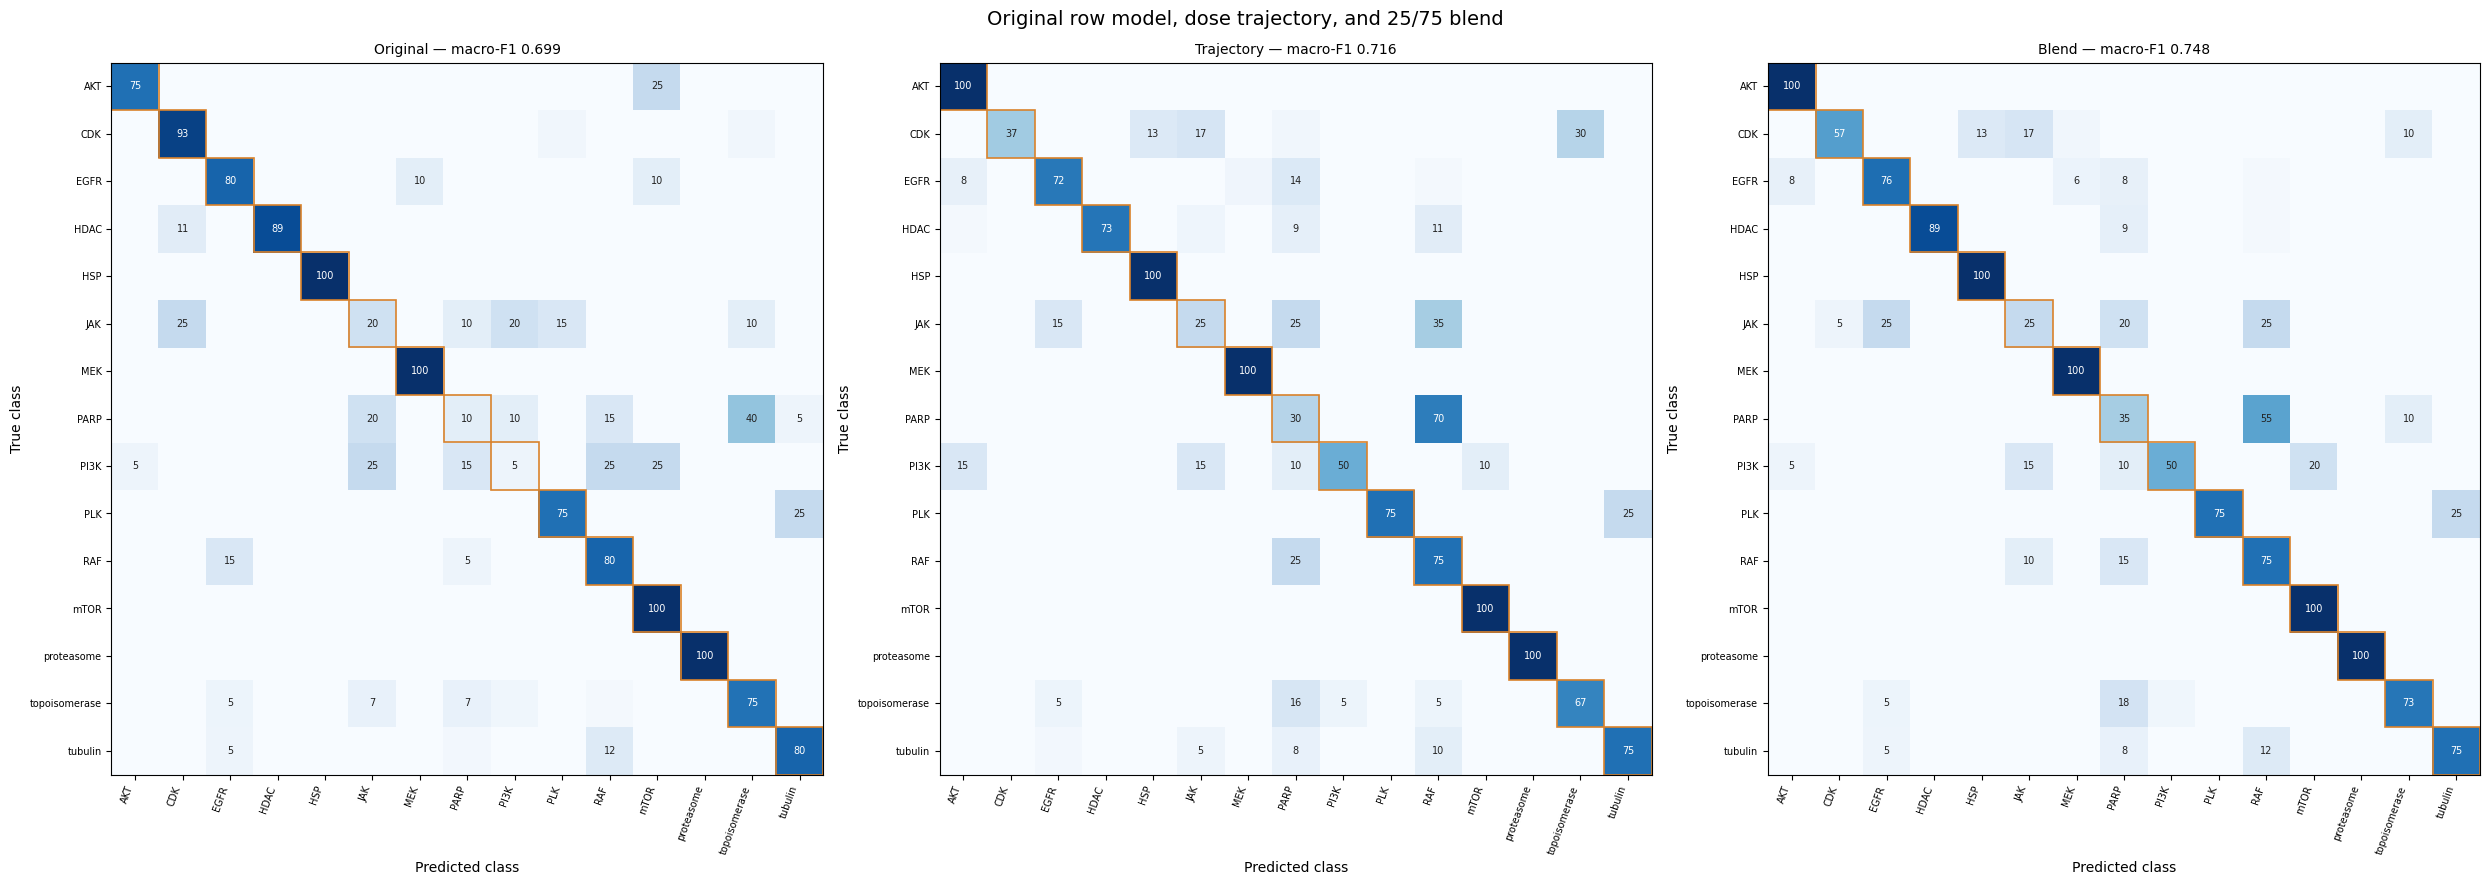

Saved: /Users/yusufberkoruc/Desktop/BioHackathon2026-Omics/analysis/plots/notebook_original_trajectory_blend_confusion.png


In [9]:
def short_label(label):
    return label.replace(" inhibitor", "").replace(" polymerization", "")


def draw_confusion(ax, matrix, labels, title):
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    for row in range(len(labels)):
        for column in range(len(labels)):
            value = matrix[row, column]
            if value >= 0.05:
                ax.text(
                    column, row, f"{value * 100:.0f}",
                    ha="center", va="center", fontsize=7,
                    color="white" if value > 0.55 else "#222222",
                )
        ax.add_patch(plt.Rectangle(
            (row - 0.5, row - 0.5), 1, 1,
            fill=False, edgecolor="#d9822b", linewidth=1.2,
        ))
    ax.set_xticks(range(len(labels)), labels, rotation=70, ha="right", fontsize=7)
    ax.set_yticks(range(len(labels)), labels, fontsize=7)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.grid(False)
    ax.set_title(title, fontsize=10)


short_classes = [short_label(label) for label in classes]
fig, axes = plt.subplots(1, 3, figsize=(25, 8.5))
for ax, model_name in zip(axes, ["original", "trajectory", "blend"]):
    frame = oof[oof["model"].eq(model_name)]
    predicted = class_array[frame[classes].to_numpy().argmax(axis=1)]
    counts = confusion_matrix(frame["true"], predicted, labels=classes)
    normalized = counts / counts.sum(axis=1, keepdims=True)
    pd.DataFrame(counts, index=classes, columns=classes).to_csv(
        RESULTS / f"notebook_confusion_{model_name}_counts.csv"
    )
    pd.DataFrame(normalized, index=classes, columns=classes).to_csv(
        RESULTS / f"notebook_confusion_{model_name}_row_normalized.csv"
    )
    draw_confusion(
        ax,
        normalized,
        short_classes,
        f"{model_name.title()} — macro-F1 {summary.loc[model_name, 'macro_f1_mean']:.3f}",
    )

fig.suptitle("Original row model, dose trajectory, and 25/75 blend", fontsize=14, y=0.995)
fig.tight_layout()
figure_path = PLOTS / "notebook_original_trajectory_blend_confusion.png"
fig.savefig(figure_path, dpi=130, bbox_inches="tight")
plt.show()
print("Saved:", figure_path)

## 10. Retrain on all labeled compounds and predict the test compounds

This final section applies exactly the same fixed models to all available labeled compounds. It writes three probability files with one row per test compound and the 15 columns from `classes.txt`. The files are intentionally named separately and do not replace `submission.csv`.

In [10]:
# Original model on all eligible rows
training_rows = (doses >= 0.37) | train_control
test_rows = meta_test["dose_um"].to_numpy(float) >= 0.37
all_row_labels = label_values[training_rows]
all_row_weights = balanced_row_weights(
    all_row_labels,
    train_control[training_rows],
    real_rows=int((~train_control).sum()),
    real_compounds=len(compound_truth),
)
original_test_rows = row_ensemble_probability(
    x_train[training_rows][:, genes],
    all_row_labels,
    all_row_weights,
    x_test[test_rows][:, genes],
    classes,
)
original_test = aggregate_rows(
    original_test_rows, meta_test.index[test_rows], meta_test, classes
)

# Trajectory model on all 86 labeled compounds
all_compound_weights = balanced_compound_weights(compound_labels)
trajectory_test_probability = trajectory_ensemble_probability(
    trajectory_train.to_numpy(),
    compound_labels,
    all_compound_weights,
    trajectory_test.to_numpy(),
    classes,
)
trajectory_test_frame = pd.DataFrame(
    trajectory_test_probability,
    index=trajectory_test.index,
    columns=classes,
).loc[original_test.index]

blend_test = (
    (1 - TRAJECTORY_WEIGHT) * original_test
    + TRAJECTORY_WEIGHT * trajectory_test_frame
)
blend_test = blend_test.div(blend_test.sum(axis=1), axis=0)

test_outputs = {
    "original": original_test,
    "trajectory": trajectory_test_frame,
    "blend": blend_test,
}
for name, frame in test_outputs.items():
    frame.index.name = "compound"
    path = RESULTS / f"submission_notebook_{name}.csv"
    frame.reset_index().to_csv(path, index=False)
    assert frame.shape == (29, 15)
    assert np.allclose(frame.sum(axis=1), 1.0)
    print(f"{name:10s} -> {path.name}; probability sums valid")

original   -> submission_notebook_original.csv; probability sums valid
trajectory -> submission_notebook_trajectory.csv; probability sums valid
blend      -> submission_notebook_blend.csv; probability sums valid


## 11. Inspect the resulting test calls

The hidden test labels are unavailable, so these counts are diagnostics rather than performance measurements. A surprising class distribution is a reason for caution, not proof that a model is incorrect.

In [11]:
prediction_table = pd.DataFrame({
    name: frame.idxmax(axis=1)
    for name, frame in test_outputs.items()
})
display(prediction_table)

print("Blend argmax class counts:")
display(prediction_table["blend"].value_counts().rename("compounds").to_frame())

,original,trajectory,blend
compound,,,
BRD-A03506276,HSP inhibitor,HSP inhibitor,HSP inhibitor
BRD-A33280134,topoisomerase inhibitor,topoisomerase inhibitor,topoisomerase inhibitor
BRD-A36331462,proteasome inhibitor,proteasome inhibitor,proteasome inhibitor
BRD-K02389548,HDAC inhibitor,HDAC inhibitor,HDAC inhibitor
BRD-K05804044,MEK inhibitor,MEK inhibitor,MEK inhibitor
BRD-K11153516,tubulin polymerization inhibitor,RAF inhibitor,RAF inhibitor
BRD-K12423485,CDK inhibitor,PARP inhibitor,PARP inhibitor
BRD-K13154216,mTOR inhibitor,mTOR inhibitor,mTOR inhibitor
BRD-K13390322,CDK inhibitor,CDK inhibitor,CDK inhibitor


Blend argmax class counts:


,compounds
blend,
PARP inhibitor,6
HDAC inhibitor,3
MEK inhibitor,3
tubulin polymerization inhibitor,3
EGFR inhibitor,3
HSP inhibitor,2
proteasome inhibitor,2
RAF inhibitor,2
CDK inhibitor,2


## Interpretation

- The **original model** recognizes endpoint expression signatures and is particularly strong for several easy mechanisms.
- The **trajectory model** uses unlabeled-data PCA modules to compare response amplitude, activation threshold, slope, saturation, and reversal across doses.
- The **blend** works when those two representations make complementary mistakes. Its higher macro-F1 mainly comes from recovering difficult classes, even when ordinary accuracy changes little.
- Repeated folds are still different partitions of the same 86 compounds; they are not a fully independent biological validation cohort.